# BiomedCLIP: zero-shot image-text comparison

Model: [`microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224`](https://huggingface.co/microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224)

Steps:
1. Check that the notebook runs inside the project's `.venv`
2. Import libraries and check the available hardware
3. Load the pretrained model, the image preprocessing function and the text tokenizer
4. Download the 9 test images that ship with the model repository
5. Prepare text prompts and images
6. Encode both, compare them, and visualise the result

> Run `python setup_env.py` once first (creates `.venv`, installs the libraries, registers the kernel
> **Python (.venv BiomedCLIP)**), then select that kernel for this notebook.

## 1. Check the environment

In [1]:
import sys
from pathlib import Path

print("Python     :", sys.version.split()[0])
print("Interpreter:", sys.executable)

in_venv = sys.prefix != getattr(sys, "base_prefix", sys.prefix)
in_project_venv = ".venv" in Path(sys.prefix).parts
print("Inside a virtual environment :", in_venv)
print("Inside the project's .venv   :", in_project_venv)
if not in_project_venv:
    print("\nWARNING: this kernel is not the project's .venv. "
          "Run `python setup_env.py` and select the kernel 'Python (.venv BiomedCLIP)'.")

Python     : 3.11.0
Interpreter: c:\Users\zakar\OneDrive\Bureau\AI4VIS\.venv\Scripts\python.exe
Inside a virtual environment : True
Inside the project's .venv   : True


## 2. Imports and hardware check

In [3]:
import os
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import torch
import transformers
from huggingface_hub import hf_hub_download
from open_clip import create_model_from_pretrained, get_tokenizer
from PIL import Image
from importlib.metadata import version as pkg_version

warnings.filterwarnings("ignore", category=UserWarning)

print(f"torch {torch.__version__} | open_clip_torch {pkg_version('open_clip_torch')} | "
      f"transformers {transformers.__version__} | numpy {np.__version__}")
print(f"OS  : {platform.system()} {platform.release()} ({platform.machine()})")
print(f"CPU : {os.cpu_count()} logical cores, torch threads = {torch.get_num_threads()}")
try:
    import psutil
    print(f"RAM : {psutil.virtual_memory().total / 1e9:.1f} GB total, "
          f"{psutil.virtual_memory().available / 1e9:.1f} GB free")
except ImportError:
    pass

cuda_ok = torch.cuda.is_available()
mps_ok = bool(getattr(torch.backends, "mps", None)) and torch.backends.mps.is_available()

if cuda_ok:
    device = torch.device("cuda")
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        print(f"GPU {i}: {p.name} | {p.total_memory / 1e9:.1f} GB | compute capability {p.major}.{p.minor}")
    print("CUDA runtime:", torch.version.cuda)
elif mps_ok:
    device = torch.device("mps")
    print("GPU : Apple Silicon (Metal / MPS)")
else:
    device = torch.device("cpu")
    print("GPU : none found, using CPU (fine for this demo, just slower)")

print("\n-> Using device:", device)

torch 2.15.0+cpu | open_clip_torch 2.23.0 | transformers 4.35.2 | numpy 1.26.4
OS  : Windows 10 (AMD64)
CPU : 4 logical cores, torch threads = 2
RAM : 8.5 GB total, 0.9 GB free
GPU : none found, using CPU (fine for this demo, just slower)

-> Using device: cpu


## 3. Load the model, preprocessing function and tokenizer

`create_model_from_pretrained` returns the model together with the **image preprocessing transform**
(resize/crop to 224x224 and normalise). `get_tokenizer` returns the PubMedBERT text tokenizer.
Weights are downloaded from the Hugging Face Hub on the first run and cached afterwards.

In [5]:
MODEL_ID = "hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"

model, preprocess = create_model_from_pretrained(MODEL_ID)
tokenizer = get_tokenizer(MODEL_ID)

model = model.to(device).eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"Model loaded: {type(model).__name__}, {n_params / 1e6:.1f}M parameters, on {next(model.parameters()).device}")
print("Tokenizer   :", type(tokenizer).__name__)
print("\nImage preprocessing pipeline:")
print(preprocess)

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


open_clip_pytorch_model.bin:   0%|          | 0.00/784M [00:00<?, ?B/s]

open_clip_config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

c:\Users\zakar\OneDrive\Bureau\AI4VIS\.venv\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

c:\Users\zakar\OneDrive\Bureau\AI4VIS\.venv\Lib\site-packages\transformers\utils\generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Model loaded: CustomTextCLIP, 195.9M parameters, on cpu
Tokenizer   : HFTokenizer

Image preprocessing pipeline:
Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_to_rgb at 0x000001F991830400>
    ToTensor()
    Normalize(mean=[0.48145466, 0.4578275, 0.40821073], std=[0.26862954, 0.26130258, 0.27577711])
)


## 4. Get the test images provided with BiomedCLIP

The model repository contains `example_data/biomed_image_classification_example_data/` with nine images
(histopathology, X-ray, MRI, plus two non-medical charts as negatives). The filename tells us the expected label.

adenocarcinoma_histopathology.jpg:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

brain_MRI.jpg:   0%|          | 0.00/128k [00:00<?, ?B/s]

covid_line_chart.png:   0%|          | 0.00/6.30k [00:00<?, ?B/s]

(…)amous_cell_carcinoma_histopathology.jpeg:   0%|          | 0.00/17.2k [00:00<?, ?B/s]

IHC_histopathology.jpg:   0%|          | 0.00/181k [00:00<?, ?B/s]

bone_X-ray.jpg:   0%|          | 0.00/7.44k [00:00<?, ?B/s]

chest_X-ray.jpg:   0%|          | 0.00/906k [00:00<?, ?B/s]

pie_chart.png:   0%|          | 0.00/371k [00:00<?, ?B/s]

H_and_E_histopathology.jpg:   0%|          | 0.00/177k [00:00<?, ?B/s]

Downloaded 9 images to the local Hugging Face cache.


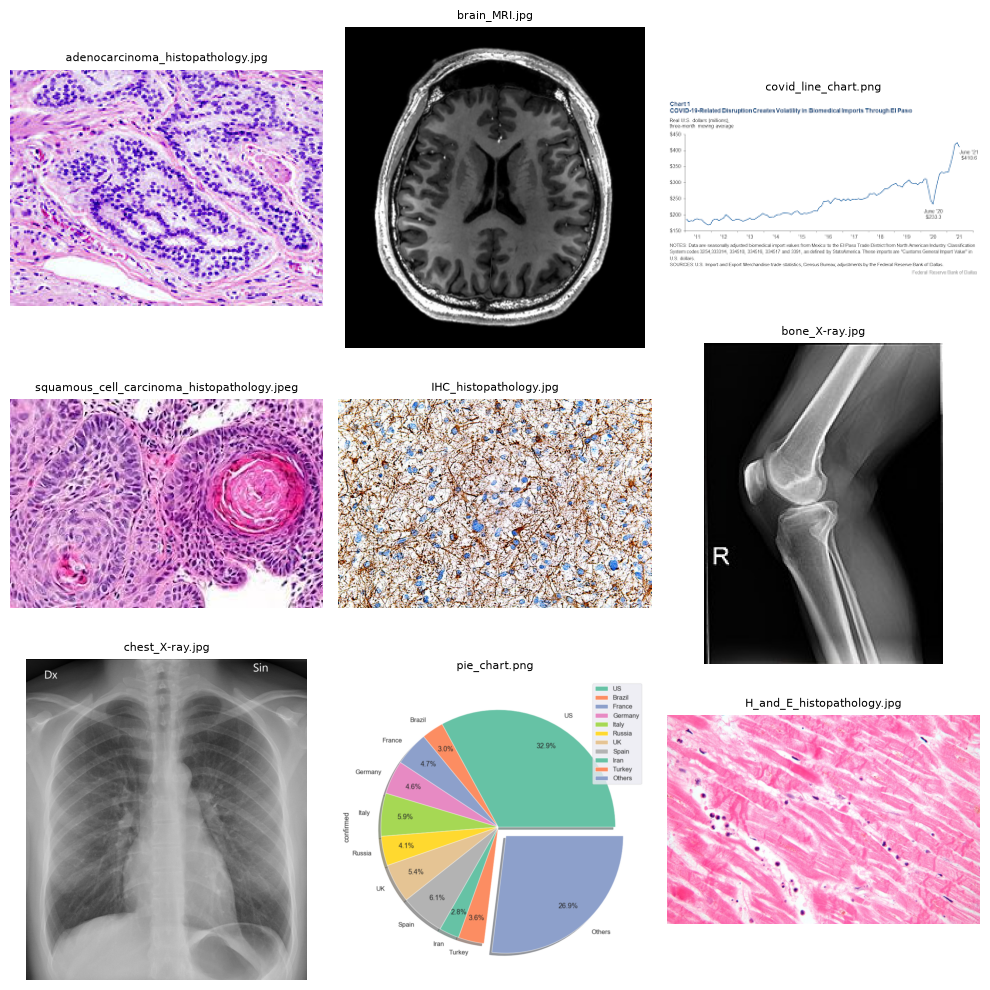

In [6]:
REPO_ID = "microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"
EXAMPLE_DIR = "example_data/biomed_image_classification_example_data"

# file name -> expected label (taken from the file name; used only to score the result)
EXPECTED = {
    "adenocarcinoma_histopathology.jpg": "adenocarcinoma histopathology",
    "brain_MRI.jpg": "brain MRI",
    "covid_line_chart.png": "covid line chart",
    "squamous_cell_carcinoma_histopathology.jpeg": "squamous cell carcinoma histopathology",
    "IHC_histopathology.jpg": "immunohistochemistry histopathology",
    "bone_X-ray.jpg": "bone X-ray",
    "chest_X-ray.jpg": "chest X-ray",
    "pie_chart.png": "pie chart",
    "H_and_E_histopathology.jpg": "hematoxylin and eosin histopathology",
}

image_paths = {name: hf_hub_download(REPO_ID, f"{EXAMPLE_DIR}/{name}") for name in EXPECTED}
print(f"Downloaded {len(image_paths)} images to the local Hugging Face cache.")

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, (name, path) in zip(axes.ravel(), image_paths.items()):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(name, fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Prepare text and images

* **Text:** every candidate label is wrapped in the prompt template `"this is a photo of <label>"` and tokenised
  with `context_length=256` (the length BiomedCLIP was trained with).
* **Images:** each image is converted to RGB and passed through `preprocess`, then stacked into one batch tensor.

In [7]:
CONTEXT_LENGTH = 256
TEMPLATE = "this is a photo of "

# One candidate label per test image (order here is the column order of the results below)
LABELS = list(EXPECTED.values())

prompts = [TEMPLATE + label for label in LABELS]
texts = tokenizer(prompts, context_length=CONTEXT_LENGTH).to(device)

images = torch.stack(
    [preprocess(Image.open(path).convert("RGB")) for path in image_paths.values()]
).to(device)

print("Example prompt    :", prompts[0])
print("Token tensor      :", tuple(texts.shape), texts.dtype, "(prompts x context_length)")
print("First 12 token ids:", texts[0, :12].tolist())
print("Image tensor      :", tuple(images.shape), images.dtype, "(images x channels x H x W)")

Example prompt    : this is a photo of adenocarcinoma histopathology
Token tensor      : (9, 256) torch.int64 (prompts x context_length)
First 12 token ids: [2, 1805, 1744, 42, 7745, 1685, 7804, 12997, 3, 0, 0, 0]
Image tensor      : (9, 3, 224, 224) torch.float32 (images x channels x H x W)


## 6. Encode and compare

The model returns L2-normalised image features, text features and the learned temperature (`logit_scale`).
The similarity of every image to every prompt is the scaled dot product (cosine similarity x temperature);
a softmax over the prompts turns each image's row into probabilities.

In [8]:
with torch.no_grad():
    image_features, text_features, logit_scale = model(images, texts)

    cosine = image_features @ text_features.t()             # raw cosine similarity, images x prompts
    probs = (logit_scale * cosine).softmax(dim=-1).cpu()    # softmax over prompts for each image

cosine = cosine.cpu()
print("image_features:", tuple(image_features.shape), "| text_features:", tuple(text_features.shape),
      f"| logit_scale: {float(logit_scale):.2f}")
print("feature L2 norms (should be ~1):",
      image_features.norm(dim=-1)[:3].cpu().numpy().round(3),
      text_features.norm(dim=-1)[:3].cpu().numpy().round(3))

names = list(image_paths)
sorted_idx = torch.argsort(probs, dim=-1, descending=True)

correct = 0
print(f"\n{'image':<48} {'top-1 prediction':<42} prob   ok")
print("-" * 100)
for i, name in enumerate(names):
    top = sorted_idx[i, 0].item()
    ok = LABELS[top] == EXPECTED[name]
    correct += ok
    print(f"{name:<48} {LABELS[top]:<42} {probs[i, top]:.3f}  {'Y' if ok else 'N'}")
print(f"\nTop-1 accuracy: {correct}/{len(names)} = {correct / len(names):.0%}")

print("\nTop-3 per image:")
for i, name in enumerate(names):
    top3 = ", ".join(f"{LABELS[j]} ({probs[i, j]:.2f})" for j in sorted_idx[i, :3].tolist())
    print(f"  {name}: {top3}")

image_features: (9, 512) | text_features: (9, 512) | logit_scale: 85.23
feature L2 norms (should be ~1): [1. 1. 1.] [1. 1. 1.]

image                                            top-1 prediction                           prob   ok
----------------------------------------------------------------------------------------------------
adenocarcinoma_histopathology.jpg                adenocarcinoma histopathology              0.732  Y
brain_MRI.jpg                                    brain MRI                                  1.000  Y
covid_line_chart.png                             covid line chart                           1.000  Y
squamous_cell_carcinoma_histopathology.jpeg      squamous cell carcinoma histopathology     0.997  Y
IHC_histopathology.jpg                           immunohistochemistry histopathology        0.997  Y
bone_X-ray.jpg                                   bone X-ray                                 0.999  Y
chest_X-ray.jpg                                  chest X-ray   

### Visualise: similarity matrices and best matches

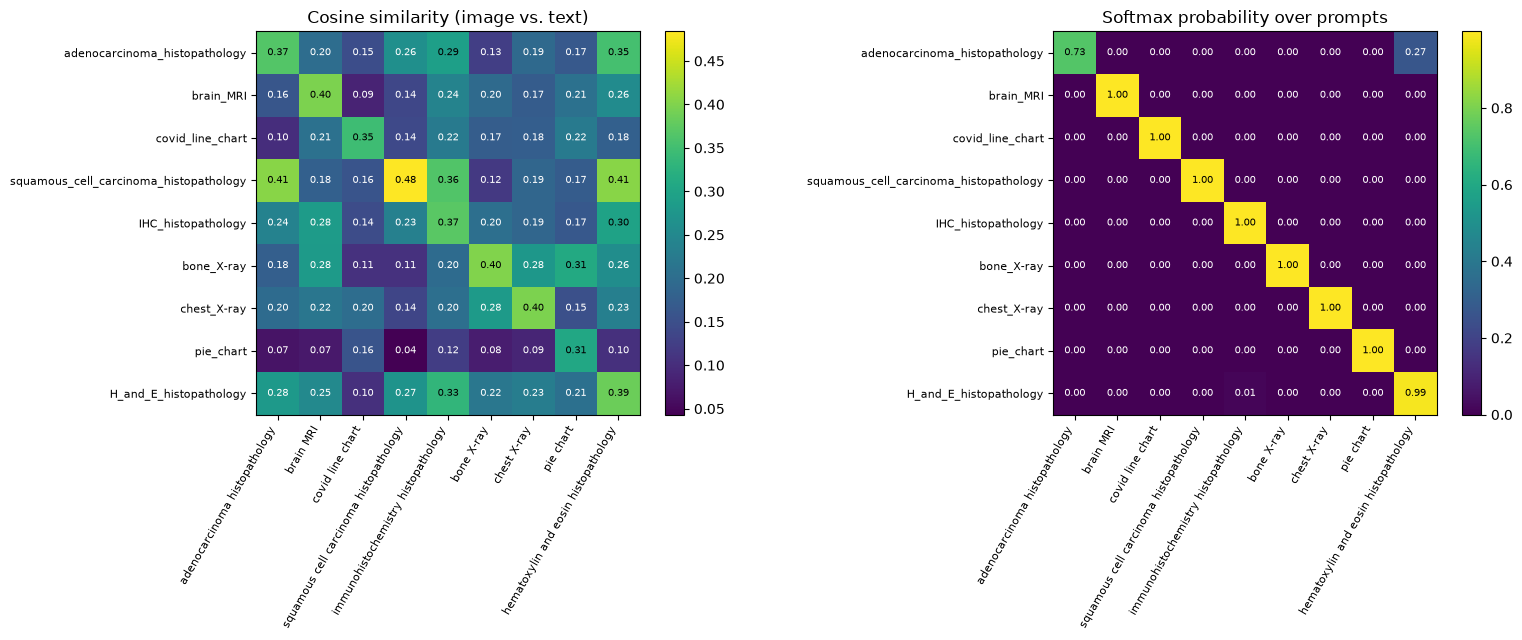

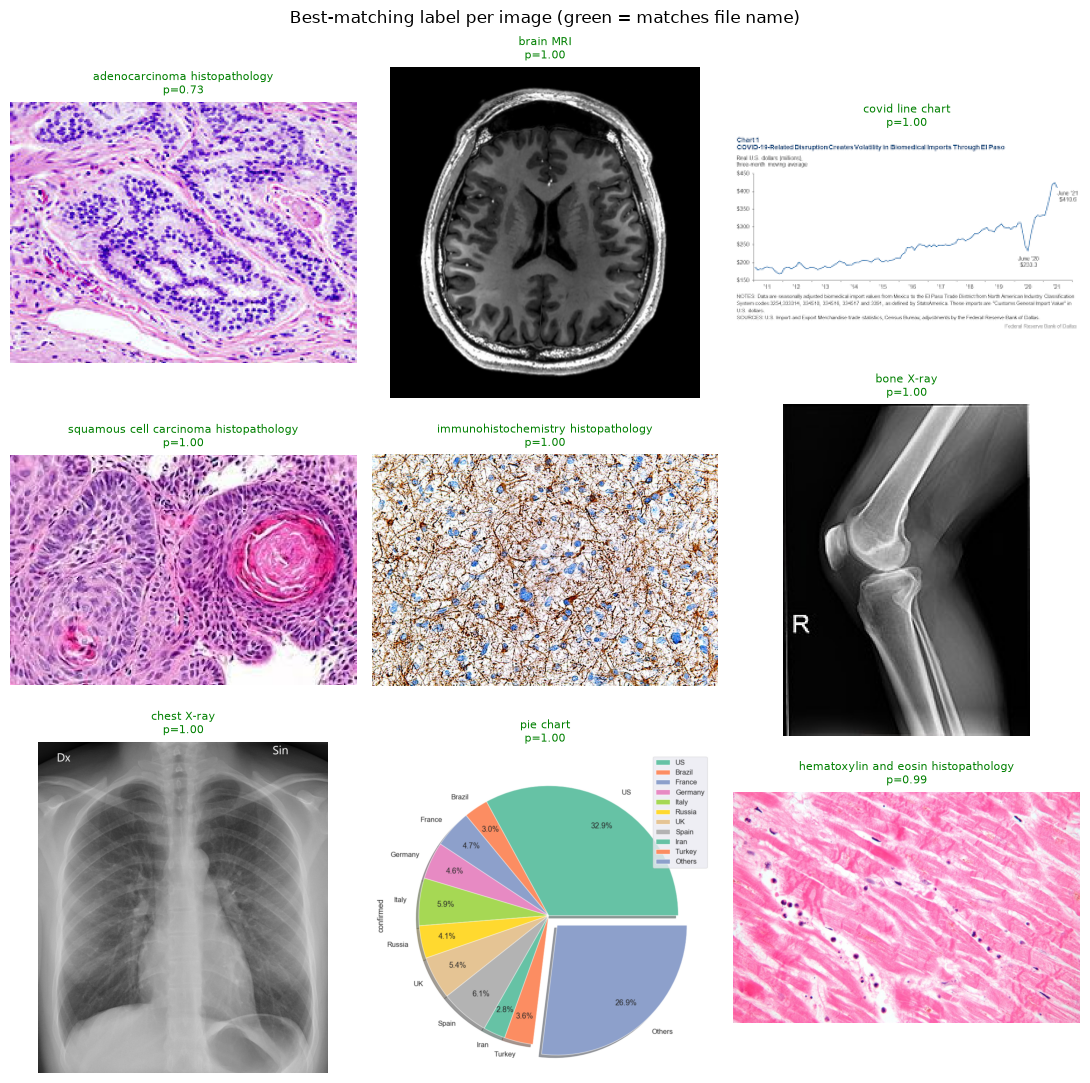

In [9]:
short = [n.rsplit(".", 1)[0] for n in names]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, mat, title, fmt in [
    (axes[0], cosine.numpy(), "Cosine similarity (image vs. text)", "{:.2f}"),
    (axes[1], probs.numpy(), "Softmax probability over prompts", "{:.2f}"),
]:
    im = ax.imshow(mat, cmap="viridis")
    ax.set_xticks(range(len(LABELS)), labels=LABELS, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(short)), labels=short, fontsize=8)
    ax.set_title(title)
    for r in range(mat.shape[0]):
        for c in range(mat.shape[1]):
            ax.text(c, r, fmt.format(mat[r, c]), ha="center", va="center",
                    color="white" if mat[r, c] < mat.max() * 0.6 else "black", fontsize=7)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for ax, (i, (name, path)) in zip(axes.ravel(), enumerate(image_paths.items())):
    top = sorted_idx[i, 0].item()
    ok = LABELS[top] == EXPECTED[name]
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(f"{LABELS[top]}\np={probs[i, top]:.2f}", fontsize=8, color="green" if ok else "red")
    ax.axis("off")
plt.suptitle("Best-matching label per image (green = matches file name)")
plt.tight_layout()
plt.show()

## 7. Try your own image and labels

Edit `MY_IMAGE` and `MY_LABELS`. Prompts use the same template and tokenizer as above.

In [10]:
def classify(image_path, labels, template=TEMPLATE, top_k=3):
    """Zero-shot classify one image against free-text labels with BiomedCLIP."""
    img = preprocess(Image.open(image_path).convert("RGB")).unsqueeze(0).to(device)
    tok = tokenizer([template + l for l in labels], context_length=CONTEXT_LENGTH).to(device)
    with torch.no_grad():
        f_img, f_txt, scale = model(img, tok)
        p = (scale * f_img @ f_txt.t()).softmax(dim=-1)[0].cpu()
    order = torch.argsort(p, descending=True)[:top_k]
    return [(labels[j], float(p[j])) for j in order.tolist()]


MY_IMAGE = image_paths["chest_X-ray.jpg"]          # replace with the path to your own image
MY_LABELS = ["chest X-ray", "brain MRI", "abdominal CT", "ultrasound", "histopathology slide"]

for label, p in classify(MY_IMAGE, MY_LABELS):
    print(f"{p:.3f}  {label}")

1.000  chest X-ray
0.000  ultrasound
0.000  abdominal CT
